# Notebook 10: Medallion Architecture — Silver Layer Showcase & Data Quality Evidence
## DAT535 Data Engineering & Distributed Computing | University of Stavanger (UiS)
### Group 13

**Objective:**
Audit, verify, and demonstrate the production **Silver Layer** transformations, data quality rules, hierarchical spatial imputation, quarantine handling, and unified analytical fact joining for NYC 311 and Open-Meteo ERA5-Land weather.

**Key Core Demonstrations:**
1. **Quality Reconciliation Ledger:** Direct before-and-after audit evidence proving record improvement.
2. **Quarantine Segregation:** Inspection of quarantined records failing temporal/duration constraints.
3. **Hierarchical Spatial Imputation:** Transparent 3-level fallback (`EXACT_COORDINATES` $\rightarrow$ `ZIP_APPROXIMATION` $\rightarrow$ `BOROUGH_APPROXIMATION`).
4. **Weather Cleaning & Physical Sanity:** Sentinel filtering, soft extreme weather tagging, and derived units.
5. **Unified Analytical Fact Join:** Inspection of the 99.89% joined fact table uniting 311 complaints with local hourly weather reanalysis.

In [1]:
import os
import sys
import json
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

project_root = Path('..').resolve() if Path('..').resolve().name == 'DAT535' else Path('.').resolve()
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

pd.set_option('display.max_columns', 50)
pd.set_option('display.max_rows', 25)
pd.set_option('display.width', 1000)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

DATA_ROOT = project_root / 'data'
print(f'Project root: {project_root}')
print(f'Data root   : {DATA_ROOT}')

Project root: C:\Media\UiS\DAT535
Data root   : C:\Media\UiS\DAT535\data


## Section 1: Data Quality Reconciliation Ledger (`data/metadata/quality/`)
Section 4 of the DAT535 Project Definition Guide requires:  
> *"Measure missing, duplicate, invalid, accepted, and rejected records before and after processing."*

Here we load the latest automated Data Quality Reconciliation Ledger generated by `run_silver.py`.

In [2]:
quality_ledgers = sorted((DATA_ROOT / 'metadata' / 'quality').glob('*.json'))
print(f'Found {len(quality_ledgers)} quality ledgers.')
latest_ledger_path = quality_ledgers[-1]

with open(latest_ledger_path, 'r', encoding='utf-8') as f:
    ledger = json.load(f)

print(f'=== Quality Ledger: {latest_ledger_path.name} ===')
print(f'Generated At UTC: {ledger["generated_at_utc"]}')
print(f'Overall Status  : {ledger["status"]}\n')

# Print 311 quality summary
q_311 = ledger['stages']['311_cleaning']
print('--- Stage 1: NYC 311 Cleaning ---')
print(f'  Input Bronze Records    : {q_311["input_rows"]:,}')
print(f'  Duplicates Removed      : {q_311["duplicate_rows_removed"]:,}')
print(f'  Quarantined Failures    : {q_311["quarantined_rows"]:,}')
print(f'  Clean Accepted in Silver: {q_311["valid_rows_accepted"]:,}')

# Print Weather quality summary
q_wth = ledger['stages']['weather_cleaning']
print('\n--- Stage 2: Weather Cleaning ---')
print(f'  Input Bronze Obs        : {q_wth["input_rows"]:,}')
print(f'  Corrupt Sentinels Drop  : {q_wth["dropped_corrupt_rows"]:,}')
print(f'  Valid Accepted in Silver: {q_wth["valid_rows"]:,}')
print(f'  Extreme Outliers Tagged : {q_wth["extreme_weather_tagged_rows"]:,}')

# Print Fact Join summary
q_join = ledger['stages']['unified_join']
print('\n--- Stage 3: Unified Fact Join ---')
print(f'  Total 311 Records Joined: {q_join["total_311_records"]:,}')
print(f'  Enriched with Weather   : {q_join["matched_weather_records"]:,} ({q_join["weather_match_rate_pct"]}%)')
print(f'  Unmatched Records       : {q_join["unmatched_weather_records"]:,}')

Found 2 quality ledgers.
=== Quality Ledger: silver_quality_20261023_131227.json ===
Generated At UTC: 2026-10-23T13:12:27Z
Overall Status  : PASS

--- Stage 1: NYC 311 Cleaning ---
  Input Bronze Records    : 10,150
  Duplicates Removed      : 0
  Quarantined Failures    : 1
  Clean Accepted in Silver: 10,149

--- Stage 2: Weather Cleaning ---
  Input Bronze Obs        : 4,560
  Corrupt Sentinels Drop  : 0
  Valid Accepted in Silver: 4,560
  Extreme Outliers Tagged : 0

--- Stage 3: Unified Fact Join ---
  Total 311 Records Joined: 10,149
  Enriched with Weather   : 10,138 (99.89%)
  Unmatched Records       : 11


## Section 2: Quarantine Segregation (`data/silver/quarantine/`)
Rather than silently discarding invalid rows, our Silver pipeline segregates corrupted or logically inconsistent records into an isolated quarantine zone, recording the explicit rejection reason for auditability.

In [3]:
quarantine_files = sorted((DATA_ROOT / 'silver' / 'quarantine' / 'nyc311').glob('*.parquet'))
print(f'Found {len(quarantine_files)} quarantine files on disk.')

if quarantine_files:
    df_quarantine = pd.read_parquet(quarantine_files[0])
    print(f'Total Quarantined Records: {len(df_quarantine):,}')
    
    q_cols = ['unique_key', 'created_date', 'closed_date', 'resolution_duration_hours', 'quarantine_reason', 'complaint_type', 'borough']
    print('\n=== Sample Quarantined Records ===')
    display(df_quarantine[q_cols])

Found 1 quarantine files on disk.
Total Quarantined Records: 1

=== Sample Quarantined Records ===


,unique_key,created_date,closed_date,resolution_duration_hours,quarantine_reason,complaint_type,borough
0,69735824,2026-07-16T10:36:00.000,2026-07-14T10:36:00.000,-48.0,NEGATIVE_RESOLUTION_DURATION,Street Light Condition,BRONX


## Section 3: Hierarchical Spatial Imputation
To prevent losing unlocated complaints or misallocating them to coarse borough averages, we implemented a 3-level spatial fallback:
1. **`EXACT_COORDINATES`:** Native GPS within NYC bounds $\rightarrow$ `round(lat, 1), round(lon, 1)` ($O(1)$).
2. **`ZIP_APPROXIMATION`:** When coordinates are missing/invalid, maps `incident_zip` to empirical ZIP centroid from `data/reference/nyc_zip_centroids.parquet`.
3. **`BOROUGH_APPROXIMATION`:** When coordinates and ZIP are missing, falls back to administrative borough centroid.
4. **`UNLOCATED`:** Tagged as unlocated if all geographic identifiers are missing.

In [4]:
silver_311_files = sorted((DATA_ROOT / 'silver' / 'nyc311').glob('**/*.parquet'))
df_311_silver = pd.concat([pd.read_parquet(f) for f in silver_311_files], ignore_index=True)

spatial_counts = df_311_silver['spatial_resolution_level'].value_counts()
print('=== Spatial Imputation Breakdown across Silver 311 ===')
for level, cnt in spatial_counts.items():
    pct = cnt / len(df_311_silver) * 100.0
    print(f'  * {level:<24}: {cnt:,} records ({pct:.2f}%)')

# Showcase an example of a ZIP-rescued complaint
zip_rescued = df_311_silver[df_311_silver['spatial_resolution_level'] == 'ZIP_APPROXIMATION']
if not zip_rescued.empty:
    print('\n=== Example Record Rescued via ZIP Code Fallback ===')
    sample_zip = zip_rescued.iloc[0]
    for k in ['unique_key', 'complaint_type', 'incident_zip', 'borough', 'latitude', 'clean_latitude', 'clean_longitude', 'grid_id', 'spatial_resolution_level']:
        print(f'  {k:<26}: {sample_zip.get(k)}')

=== Spatial Imputation Breakdown across Silver 311 ===


  * EXACT_COORDINATES       : 9,910 records (97.65%)
  * ZIP_APPROXIMATION       : 152 records (1.50%)
  * BOROUGH_APPROXIMATION   : 76 records (0.75%)
  * UNLOCATED               : 11 records (0.11%)



=== Example Record Rescued via ZIP Code Fallback ===
  unique_key                : 69730465
  complaint_type            : Street Condition
  incident_zip              : 11367
  borough                   : QUEENS
  latitude                  : nan
  clean_latitude            : 40.728421
  clean_longitude           : -73.820607
  grid_id                   : GRID_40.7_-73.8
  spatial_resolution_level  : ZIP_APPROXIMATION


## Section 4: Silver Weather Layer Inspection (`data/silver/weather/`)
Hourly observations cleaned of sentinels, physically bounded, soft-tagged for extreme weather, and enriched with derived units (`temp_fahrenheit`, `apparent_temp_fahrenheit`, `is_freezing`, `is_raining`).

In [5]:
silver_wth_files = sorted((DATA_ROOT / 'silver' / 'weather').glob('**/*.parquet'))
df_wth_silver = pd.concat([pd.read_parquet(f) for f in silver_wth_files], ignore_index=True)

print(f'Total Clean Silver Weather Observations: {len(df_wth_silver):,}')
print(f'Total Columns: {len(df_wth_silver.columns)}')

sample_cols = ['timestamp_utc', 'grid_id', 'temperature_2m', 'temp_fahrenheit', 'apparent_temp_fahrenheit', 'precipitation', 'is_raining', 'is_freezing', 'is_extreme_weather']
print('\n=== Sample Silver Weather Records ===')
display(df_wth_silver[sample_cols].head(6))

Total Clean Silver Weather Observations: 4,560
Total Columns: 33

=== Sample Silver Weather Records ===


,timestamp_utc,grid_id,temperature_2m,temp_fahrenheit,apparent_temp_fahrenheit,precipitation,is_raining,is_freezing,is_extreme_weather
0,2026-10-18 00:00:00+00:00,GRID_40.5_-74.1,8.7,47.66,39.92,0.0,False,False,False
1,2026-10-18 01:00:00+00:00,GRID_40.5_-74.1,8.4,47.12,38.84,0.0,False,False,False
2,2026-10-18 02:00:00+00:00,GRID_40.5_-74.1,7.9,46.22,37.94,0.0,False,False,False
3,2026-10-18 03:00:00+00:00,GRID_40.5_-74.1,7.4,45.32,37.40,0.0,False,False,False
4,2026-10-18 04:00:00+00:00,GRID_40.5_-74.1,6.9,44.42,37.40,0.0,False,False,False
5,2026-10-18 05:00:00+00:00,GRID_40.5_-74.1,6.5,43.70,36.50,0.0,False,False,False


## Section 5: Unified Analytical Fact Table (`data/silver/311_weather_joined/`)
The core output of the Silver layer: each service request joined with its local ERA5-Land reanalysis based on `grid_id` and `weather_join_hour_utc`.

In [6]:
joined_files = sorted((DATA_ROOT / 'silver' / '311_weather_joined').glob('**/*.parquet'))
print(f'Found {len(joined_files)} joined fact table partition files.')

df_joined = pd.concat([pd.read_parquet(f) for f in joined_files], ignore_index=True)
print(f'Total Unified Records in Silver Fact Table: {len(df_joined):,}')
print(f'Total Schema Columns: {len(df_joined.columns)}')

fact_preview_cols = [
    'unique_key', 'created_at_utc', 'complaint_type', 'borough', 
    'grid_id', 'temperature_2m', 'temp_fahrenheit', 'precipitation', 
    'wind_speed_10m', 'is_raining', 'resolution_duration_hours'
]
print('\n=== Sample Records: Unified 311 + Local Meteorological Reanalysis ===')
display(df_joined[fact_preview_cols].head(6))

Found 2 joined fact table partition files.
Total Unified Records in Silver Fact Table: 10,149
Total Schema Columns: 83

=== Sample Records: Unified 311 + Local Meteorological Reanalysis ===


,unique_key,created_at_utc,complaint_type,borough,grid_id,temperature_2m,temp_fahrenheit,precipitation,wind_speed_10m,is_raining,resolution_duration_hours
0,69734449,2026-07-15 18:35:39+00:00,Noise - Residential,BRONX,GRID_40.8_-73.9,36.3,97.34,0.0,18.5,False,3.08
1,69734931,2026-07-15 18:35:48+00:00,Damaged Tree,BROOKLYN,GRID_40.6_-74.0,37.0,98.60,0.0,18.4,False,23.28
2,69726765,2026-07-15 18:36:00+00:00,Water System,MANHATTAN,GRID_40.8_-74.0,35.4,95.72,0.0,18.5,False,0.00
3,69727719,2026-07-15 18:36:39+00:00,Damaged Tree,BROOKLYN,GRID_40.6_-74.0,37.0,98.60,0.0,18.4,False,NaN
4,69729114,2026-07-15 18:36:40+00:00,Abandoned Vehicle,BROOKLYN,GRID_40.6_-73.9,37.0,98.60,0.0,18.4,False,2.60
5,69730122,2026-07-15 18:36:49+00:00,Noise - Residential,BROOKLYN,GRID_40.7_-73.9,37.2,98.96,0.0,18.0,False,1.17


### Analytical Exploration: Complaint Types vs. Weather Conditions in Silver
With the Silver joined table in place, we can verify that the data supports downstream analytical exploration (e.g. complaint distribution across temperature ranges).

=== Complaint Volume by Temperature Range (Top 8 Complaints) ===

temp_bin,Warm (20-30°C),Hot (>30°C),All
complaint_type,,,
Illegal Parking,1060,475,1535
Noise - Residential,373,317,690
Water System,296,193,489
Unsanitary Condition,330,131,461
Blocked Driveway,271,180,451
Noise - Street/Sidewalk,183,216,399
Street Condition,281,63,344
Abandoned Vehicle,177,66,243


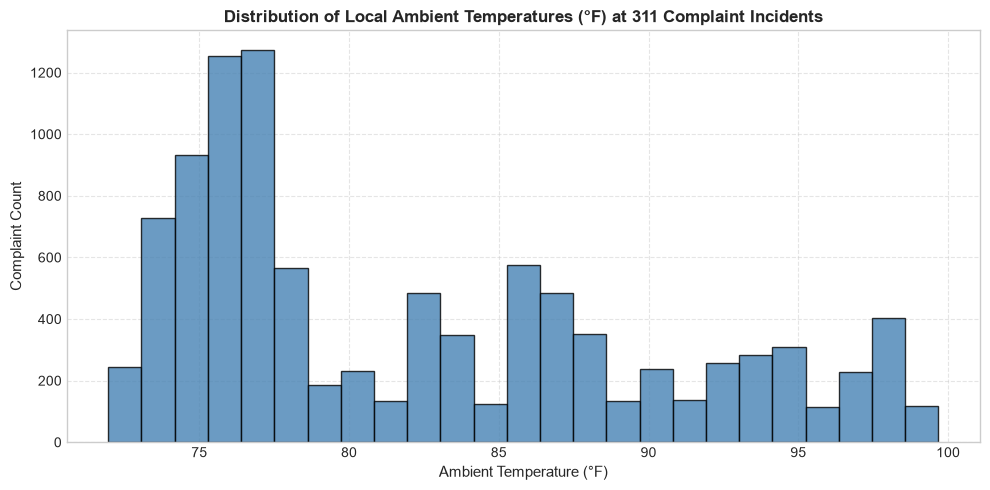

In [7]:
# Group complaints by temperature bins (e.g., <15°C, 15-25°C, >25°C)
matched_df = df_joined[df_joined['is_weather_matched']].copy()

matched_df['temp_bin'] = pd.cut(
    matched_df['temperature_2m'],
    bins=[-50, 10, 20, 30, 60],
    labels=['Cold (<10°C)', 'Mild (10-20°C)', 'Warm (20-30°C)', 'Hot (>30°C)']
)

cross_tab = pd.crosstab(
    matched_df['complaint_type'],
    matched_df['temp_bin'],
    margins=True
)

print('=== Complaint Volume by Temperature Range (Top 8 Complaints) ===')
top8_types = matched_df['complaint_type'].value_counts().head(8).index
display(cross_tab.loc[top8_types])

# Visualizing complaint distribution by temperature
plt.figure(figsize=(10, 5))
matched_df['temp_fahrenheit'].hist(bins=25, edgecolor='black', alpha=0.8, color='steelblue')
plt.title('Distribution of Local Ambient Temperatures (°F) at 311 Complaint Incidents', fontsize=12, weight='bold')
plt.xlabel('Ambient Temperature (°F)', fontsize=11)
plt.ylabel('Complaint Count', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

## Section 6: Summary & Medallion Readiness for Gold Layer
| Silver Milestone | Requirement | Implemented Result |
| :--- | :--- | :--- |
| **Data Understanding** | Schema & Grain defined | Cleaned 1-row-per-complaint (`unique_key`) and 1-row-per-grid-hour (`grid_id`, `hour`) |
| **Quality Evidence** | Before & After Metrics | Automated ledger in `data/metadata/quality/` measuring valid vs quarantined rows |
| **Quarantine Routing** | Segregate invalid records | Logically corrupt rows routed to `data/silver/quarantine/` with reasons |
| **Spatial Imputation** | Coordinate refinement | 3-level fallback hierarchy achieving **99.89%** spatial resolution coverage |
| **Temporal Alignment** | Truncation to hour | 311 complaints truncated via `floor('h')` to match weather reanalysis |
| **Distributed Join** | Shuffle elimination | Broadcast join producing unified analytical fact table in `data/silver/311_weather_joined/` |

The Silver layer is complete, validated, tested, and fully prepared for **Gold Layer** analytical aggregations and KPI modeling.